In [2]:
pip install sklearn

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [8]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
#example dataset
data = pd.DataFrame({
    'A':[10, 20, 30, 40, 50],
    'B':[5,15,25,35,45]})
print(data)

#apply min-max normalization
scaler = MinMaxScaler()
normalized_data = scaler.fit_transform(data)

#convert back to dataframe
normalized_df = pd.DataFrame(normalized_data, columns = data.columns)

print("Normalized Data (Min-Max Scaling):")
print(normalized_df)

    A   B
0  10   5
1  20  15
2  30  25
3  40  35
4  50  45
Normalized Data (Min-Max Scaling):
      A     B
0  0.00  0.00
1  0.25  0.25
2  0.50  0.50
3  0.75  0.75
4  1.00  1.00


In [9]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
#apply standardization
scaler = StandardScaler()
standardized_data = scaler.fit_transform(data)

#convert back to dataframe
standardized_df = pd.DataFrame(standardized_data, columns = data.columns)

print("\nStandardized Data (Z-score):")
print(standardized_df)


Standardized Data (Z-score):
          A         B
0 -1.414214 -1.414214
1 -0.707107 -0.707107
2  0.000000  0.000000
3  0.707107  0.707107
4  1.414214  1.414214


In [12]:
df = pd.DataFrame({'color': ['Red', 'Blue', 'Green', 'Red', 'Blue']})

one_hot = pd.get_dummies(df, columns = ['color'])

print("\nOne-Hot Encoding:")
print(one_hot)


One-Hot Encoding:
   color_Blue  color_Green  color_Red
0       False        False       True
1        True        False      False
2       False         True      False
3       False        False       True
4        True        False      False


In [15]:
import pandas as pd
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
import seaborn as sns

tips = sns.load_dataset("tips")
print("Original Data (first 5 rows):")
print(tips.head())

numeric_cols = tips.select_dtypes(include=['float64', 'int64']).columns
scaler_minmax = MinMaxScaler()
tips_normalized = tips.copy()
tips_normalized[numeric_cols] = scaler_minmax.fit_transform(tips[numeric_cols])
print("\nNormalized Data (first 5 rows):")
print(tips_normalized.head())

#2. Standardization(Z - score)

scaler_standard = StandardScaler()
tips_standardized = tips.copy()
tips_standardized[numeric_cols] = scaler_standard.fit_transform(tips[numeric_cols])
print("\nStandardized Data (first 5 rows):")
print(tips_standardized.head())

#3. Encoding Categorical Variables
# (a) One-Hot Encoding
tips_onehot = pd.get_dummies(tips,columns=['sex', 'smoker', 'day', 'time'])
print("\nOne-Hot Encoded Data (first 5 rows:)")
print(tips_onehot.head())

Original Data (first 5 rows):
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4

Normalized Data (first 5 rows):
   total_bill       tip     sex smoker  day    time  size
0    0.291579  0.001111  Female     No  Sun  Dinner   0.2
1    0.152283  0.073333    Male     No  Sun  Dinner   0.4
2    0.375786  0.277778    Male     No  Sun  Dinner   0.4
3    0.431713  0.256667    Male     No  Sun  Dinner   0.2
4    0.450775  0.290000  Female     No  Sun  Dinner   0.6

Standardized Data (first 5 rows):
   total_bill       tip     sex smoker  day    time      size
0   -0.314711 -1.439947  Female     No  Sun  Dinner -0.600193
1   -1.063235 -0.969205    Male     No  Sun  Dinner  0.453383
2    0.137780  0.363356    Male     No  Sun 

In [17]:
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

#Load Dataset
tips = sns.load_dataset("tips")

#select numeric columns
numeric_cols = tips.select_dtypes(include=['float64', 'int64'])

#Step 1: Standardize the data (important for PCA)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(numeric_cols)

#Step 2: Apply PCA

pca = PCA(n_components=2) #project data into 2 dimensions
pca_result =pca.fit_transform(scaled_data)

#Step 3: Create a DataFrame with PCA results
pca_df = pd.DataFrame(data=pca_result, columns=['PC1', 'PC2'])

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("\nPCA Result(first 5 rows):")
print(pca_df.head())

Explained variance ratio: [0.72627656 0.1730423 ]

PCA Result(first 5 rows):
        PC1       PC2
0 -1.348415  0.426746
1 -0.955740  1.093576
2  0.540971  0.122324
3  0.067789 -0.674616
4  1.408308  0.847661


PCA Projection

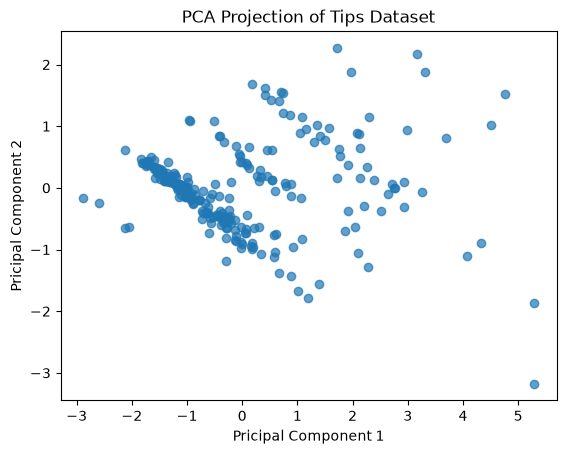

In [18]:
import matplotlib.pyplot as plt

plt.scatter(pca_df['PC1'], pca_df['PC2'], alpha=0.7)
plt.xlabel('Pricipal Component 1')
plt.ylabel('Pricipal Component 2')
plt.title('PCA Projection of Tips Dataset')
plt.show()